# **SAMson: An Automated Brain Extraction Tool for Rodents Using SAM**  
*Accurate and robust rodent brain segmentation for MRI data*

---

### **Authored by**  
**Daniel Panadero Soler**<sup>1</sup>, **Mohamed Kotb Selim**<sup>1</sup>, **Patricia Martínez-Tazo**<sup>1</sup>,  
**Emma Muñoz-Moreno**<sup>2</sup>, **Pedro Ramos-Cabrer**<sup>3,4</sup>, **Pilar López-Larrubia**<sup>5</sup>,  
**Silvia De Santis**<sup>1</sup>, **Santiago Canals**<sup>1</sup>, and **Antonio Pertusa**<sup>6</sup>  

<sup>1</sup>Instituto de Neurociencias, CSIC-UMH, Sant Joan d’Alacant, Spain  
<sup>2</sup>IDIBAPS, Barcelona, Spain  
<sup>3</sup>CIC biomaGUNE, BRTA, Donostia–San Sebastián, Spain  
<sup>4</sup>Ikerbasque, Basque Foundation for Science, Bilbao, Spain  
<sup>5</sup>Instituto de Investigaciones Biomédicas Sols-Morreale, CSIC-UAM, Madrid, Spain  
<sup>6</sup>University Institute for Computer Research, University of Alicante, Alicante, Spain  

📧 **Contact**: [pertusa@ua.es](mailto:pertusa@ua.es)  

---

### **Abstract**
**Background and objective.** Accurate brain extraction is a critical step in the analysis of rodent head magnetic resonance imaging (MRI) data. However, current methods often encounter difficulties in handling the diverse range of imaging setups, resolutions, and experimental conditions that are commonly found in this field.  
**Methods.** Based on the Segment Anything Model (SAM), we introduce here SAMson (*SAM for Segmentation Of Neuroimages*), an automated tool for robust rodent brain extraction. SAMson integrates a bounding box generator and a mask prediction pipeline, offering fully automated and semi-automated modes to address varying experimental complexities.  
**Results.** The performance of SAMson was evaluated using seven multi-center rodent MRI [datasets](https://doi.org/10.20350/digitalCSIC/17000) annotated at the pixel level, which differed in terms of acquisition parameters, contrast (T2-weighted, T2\*-weighted and diffusion-weighted images), resolution, anteroposterior coverage and animal age groups. SAMson outperformed the nine methods tested, BET, BET4Animal, RBM, BEN, SHERM, ANTs, deepbet, MedSAM and SAM2, in segmentation accuracy (significantly in 87 of 90 dataset–method comparisons), with mean Jaccard indices of 89.0–94.7%. The semi-automated mode demonstrates particular efficacy in challenging scenarios, including low-resolution images and cases requiring refined mask precision.  
**Conclusions.** In contrast to conventional volumetric techniques, SAMson's errors are confined to a few individual slices, thereby enabling rapid and targeted correction when needed. By providing open-source access, SAMson aims to support large-scale research workflows and advance translational neuroscience. The curated data can be downloaded from https://doi.org/10.20350/digitalCSIC/17000, and the code is available at https://github.com/CanalsLab/SAMson, as an installable Python package (samson-mri) with a command-line interface, a Python API and a graphical application.

---

### **Getting Started**  
To begin using SAMson, follow these steps:  
1. Install the required dependencies. Download [SAM's ViT-H model checkpoint](https://github.com/facebookresearch/segment-anything?tab=readme-ov-file#model-checkpoints) and the [Mouse-X template](https://doi.org/10.20350/digitalCSIC/17000).
2. Place your MR images in a folder, ensuring they are in NIfTI format.
3. Execute the provided initialization cells, following the usage instructions in the comments.
4. Run the fully automated mode for straightforward datasets or the semi-automated mode for challenging cases.
5. If manual masks are available, use the provided functions to assess segmentation accuracy.

## Setup

In [1]:
import os                                                                       # files
import time                                                                     # progress
import warnings                                                                 # warnings
import cv2                                                                      # images  # type: ignore
import matplotlib.pyplot as plt                                                 # plots
import numpy as np                                                              # arrays
import pandas as pd                                                             # tables
import nibabel as nib                                                           # nifti  # type: ignore
import torch                                                                    # SAM backend  # type: ignore
from os.path import join as pjoin                                               # join paths
from matplotlib.font_manager import FontProperties                              # plot titles
from segment_anything import sam_model_registry, SamPredictor                   # SAM  # type: ignore
from skimage.morphology import binary_closing, binary_erosion, binary_dilation  # mask processing
from scipy import ndimage                                                       # image processing
from dipy.segment.mask import median_otsu                                       # Otsu method  # type: ignore
warnings.filterwarnings("ignore", category=FutureWarning)                       # torch.load notice

"""""  INPUTS  (ADAPT  FOLLOWING  LINES)  """""

# ------------------           PATHS           ------------------ #
publication   = os.path.abspath("..")                                           # Release folder (this notebook is in <release>/notebooks)
template_path = pjoin(publication, "datasets/template/anat_template_FP.nii.gz")  # Path to template file
subjects_path = pjoin(publication, "datasets/D3/anat")                          # Path to folder with all subjects NIfTI files (example: D3)
output_path_b = pjoin(publication, "notebooks/SAMson_outputs")                  # Path to all outputs folder
is_subject    = lambda file: file.startswith("sub-") and file.endswith("_T2w.nii.gz")  # Condition of subject filenames (adapt it)
example_file  = "sub-20190227105648AE0818rsControl1111_T2w.nii.gz"               # Example subject: the D3 scan with the median Full-Auto Jaccard index (SAMson_experiments.ipynb)

# ----------------    ANTERO-POSTERIOR RANGE     ---------------- #
initial_slice =  3  # Index of the template slice that best matches your image's initial slice (D3: 3)
final_slice   = 35  # Index of the template slice that best matches your image's final slice (D3: 35)

"""""""""   SEGMENT  ANYTHING  MODEL   """""""""

sam_checkpoint = os.path.expanduser(os.environ.get("SAMSON_CHECKPOINT", "~/.cache/samson_mri/sam_vit_h_4b8939.pth"))  # Path to SAM model file (`samson download-model` puts it there)
device         = "cuda" if torch.cuda.is_available() else "cpu"
predictor      = SamPredictor(sam_model_registry["vit_h"](checkpoint=sam_checkpoint).to(device=device))

### SAMson functions

In [2]:
"""""""""       IMAGE  AND  MASK  UTILITIES       """""""""

def load_volume(path, reorient=False):
    """
    Load a NIfTI image as a float64 3D array (a trailing singleton 4th dimension is dropped).
    reorient=True flips the z-axis, for images whose anteroposterior axis goes from rostral to caudal.
    """
    volume = nib.load(path).get_fdata()
    if volume.ndim > 3: volume = np.squeeze(volume, axis=-1)
    return np.flip(volume, axis=2) if reorient else volume

def to_rgb(slice_2d):
    """Rotate a slice and convert it to the 8-bit RGB image SAM expects (normalised by the slice maximum)."""
    image = np.rot90(slice_2d).astype(np.float32)
    return cv2.cvtColor(((image / np.max(image)) * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)

def evaluate(mask, reference):
    """
    Accuracy (%), Jaccard index and Dice coefficient of a mask against a reference mask (0 if the reference is empty).
    Accuracy is 100 minus the percentage of disagreeing pixels relative to the reference mask size.
    """
    sam, ref = mask.astype(int), reference.astype(int)
    total = ref + sam
    if not (np.any(ref) and np.any(total)):
        return 0, 0, 0
    overlap = np.count_nonzero(total == 2)
    accuracy = 100 - round((np.count_nonzero(ref - sam) / np.count_nonzero(ref)) * 100, 2)
    jaccard  = round((overlap / np.count_nonzero(total)), 4)
    dice     = round(2 * (overlap / (np.count_nonzero(sam) + np.count_nonzero(ref))), 4)
    return accuracy, jaccard, dice

def evaluate_slices(masks, reference, slices=None):
    """
    Metrics of every candidate mask of every slice (or of the given slice indexes) against the reference volume.
    Returns a table with 1-based slice numbers (as in the plots) and 0-based candidate indexes (as in best_mask_indexes).
    """
    slices = range(len(masks)) if slices is None else slices
    rows = [(s + 1, c, *evaluate(masks[s, c], np.rot90(reference[:, :, s]))) for s in slices for c in range(masks.shape[1])]
    return pd.DataFrame(rows, columns=["slice", "candidate", "accuracy", "jaccard", "dice"])

def subject_means(metrics):
    """Subject mean accuracy, Jaccard and Dice over slices, rounded as in the article."""
    return {m: round(sum(metrics[m]) / len(metrics), d) for m, d in (("accuracy", 2), ("jaccard", 4), ("dice", 4))}

def find_best_mask_indexes(metrics):
    """Index (0, 1 or 2) of the candidate with the highest Jaccard index in each slice (first one if tied)."""
    return metrics.pivot(index="slice", columns="candidate", values="jaccard").to_numpy().argmax(axis=1).tolist()

def keep_largest_component(mask):
    """Keep only the largest connected component of a binary mask (returned as 0/1 integers)."""
    labels, _ = ndimage.label(mask)  # type: ignore
    return np.where(labels == np.argmax(np.bincount(labels.ravel())[1:]) + 1, 1, 0)

def remove_lobes_and_separate_pixels(mask, otsu=False):
    """
    Remove lobes (regions that detach from the main body after an erosion) and isolated pixel groups from a binary
    mask, with increasing footprint sizes (larger ones for the Otsu mask), keeping the largest connected component.
    """
    if np.any(mask):
        for size in ([2, 5, 20] if otsu else [1, 2, 3]):
            footprint = np.ones((size, size))
            eroded = binary_erosion(mask, footprint=footprint)
            if np.any(eroded):
                lobes = eroded.copy()
                lobes[keep_largest_component(eroded) == 1] = 0  # Eroded regions other than the main body
                mask = np.where(mask == True, 1, 0) - np.where(binary_dilation(lobes, footprint=footprint) == True, 1, 0)
            mask = keep_largest_component(mask)
    return mask

def postprocess(mask):
    """SAMson post-processing of a SAM mask: lobe and isolated pixel removal followed by a 2x2 closing."""
    return binary_closing(remove_lobes_and_separate_pixels(mask), footprint=np.ones((2, 2)))

def print_percent_done(index, total, bar_len=20):
    """Display a progress bar that updates on the same line."""
    percent_done = round((index + 1) / total * 100, 1)
    done = round(percent_done / (100 / bar_len))
    bar = f"[{'◼' * done}{' ' * (bar_len - done)}] {percent_done}%"
    if percent_done < 100:
        print(f'⏳  {bar}', end='\r')
    else:
        print(f'✅  {bar}', end=' ')


"""""""""       INPUT  PROMPT  GENERATION       """""""""

def bounding_boxes(volume, threshold=0.5):
    """Box [x_left, y_up, x_right, y_down] around the voxels above threshold in every rotated slice ([0, 0, 0, 0] if none)."""
    boxes = []
    for i in range(volume.shape[2]):
        idx = np.argwhere(np.rot90(volume[:, :, i]) > threshold)
        boxes.append([idx[:, 1].min(), idx[:, 0].min(), idx[:, 1].max(), idx[:, 0].max()] if np.any(idx) else [0, 0, 0, 0])
    return np.array(boxes)

def template_relative_coordinates(template_path):
    """
    Brain box of every template slice relative to the box of the template central slice: distances [left, up, right,
    down] from the central box centre, as fractions of the central box width and height.
    """
    edges = bounding_boxes(nib.load(template_path).get_fdata())
    xl, yu, xr, yd = edges[round(len(edges) / 2)]
    width_x, width_y = xr - xl, yd - yu
    central_x, central_y = xl + width_x / 2, yu + width_y / 2
    return np.column_stack([(central_x - edges[:, 0]) / width_x, (central_y - edges[:, 1]) / width_y,
                            (edges[:, 2] - central_x) / width_x, (edges[:, 3] - central_y) / width_y])

def generate_boxes(volume, median_radius, numpass, initial_slice, final_slice):
    """
    Box prompts [x_left, y_up, x_right, y_down] for every slice of a subject: the template box shapes, linearly
    interpolated along the anteroposterior range [initial_slice, final_slice] of the template, are scaled and centred
    on the box of the brain found by median_otsu in the subject's central slice.
    """
    z_template = np.linspace(0, 1, len(relative_coordinates))
    z_subject  = np.linspace(z_template[initial_slice], z_template[final_slice], volume.shape[2])

    # Interpolate the template relative coordinates at each subject slice (nearest slice if z matches exactly)
    previous = np.searchsorted(z_template, z_subject, side='right') - 1
    following = np.searchsorted(z_template, z_subject, side='left')
    with np.errstate(divide='ignore', invalid='ignore'):
        coordinates = relative_coordinates[previous] + (z_subject - z_template[previous])[:, None] * (
            (relative_coordinates[following] - relative_coordinates[previous]) / (z_template[following] - z_template[previous])[:, None])
    exact = previous == following
    coordinates[exact] = relative_coordinates[np.abs(z_template[None, :] - z_subject[exact, None]).argmin(axis=1)]

    # Brain box of the subject's central slice from the cleaned median_otsu mask
    _, otsu = median_otsu(volume, median_radius=median_radius, numpass=numpass)
    central_mask = remove_lobes_and_separate_pixels(np.rot90(otsu[:, :, np.abs(z_subject - 0.5).argmin()]), otsu=True)
    idx = np.argwhere(central_mask != 0)
    xl, yu, xr, yd = (idx[:, 1].min(), idx[:, 0].min(), idx[:, 1].max(), idx[:, 0].max()) if np.any(idx) else (0, 0, 0, 0)
    width_x, width_y = xr - xl, yd - yu
    central_x, central_y = xl + width_x / 2, yu + width_y / 2

    return np.column_stack([central_x - width_x * coordinates[:, 0], central_y - width_y * coordinates[:, 1],
                            central_x + width_x * coordinates[:, 2], central_y + width_y * coordinates[:, 3]])


"""""""""       MASK  PREDICTION       """""""""

def segment_volume(volume, prompt_sets, model=None, show_progress=True):
    """
    Predict and post-process SAM masks for every slice of a volume.
    prompt_sets is a list of (boxes, multimask_output) pairs: each slice is embedded once and reused for all of them.
    Returns, for each pair, an array (n_slices, 1 or 3 candidates, H, W) of binary masks.
    """
    model = model or predictor
    results = [[] for _ in prompt_sets]
    for s in range(volume.shape[2]):
        if show_progress: print_percent_done(s, volume.shape[2])
        model.set_image(to_rgb(volume[:, :, s]))
        for result, (boxes, multimask) in zip(results, prompt_sets):
            masks, _, _ = model.predict(point_coords=None, point_labels=None, box=np.array(boxes[s])[None, :], multimask_output=multimask)
            result.append([postprocess(mask) for mask in masks])
    return [np.array(result) for result in results]

def save_nifti_mask(mask_slices, reference_nifti, path, reorient=False):
    """Save one mask per slice (in plotting orientation) as a uint8 NIfTI aligned voxel-to-voxel with the input image."""
    volume = np.stack([np.rot90(mask, k=-1) for mask in mask_slices], axis=2).astype(np.uint8)  # Undo the slice rotation
    if reorient: volume = np.flip(volume, axis=2)  # Back to the anteroposterior order of the input image
    nifti = nib.Nifti1Image(volume, reference_nifti.affine, reference_nifti.header)
    nifti.set_data_dtype(np.uint8)
    nib.save(nifti, path)


"""""""""       PLOTTING  FUNCTIONS       """""""""

def show_box(box, ax):
    """Plot SAM's input box."""
    ax.add_patch(plt.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], edgecolor='green', facecolor=(0,0,0,0), lw=2))  # type: ignore

def show_mask(mask, ax, manual=False):
    """Plot a SAMson (blue) or reference (yellow) mask."""
    color = np.array([255/255, 234/255, 0/255, 0.6]) if manual else np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    ax.imshow(mask.reshape(h, w, 1) * color.reshape(1, 1, -1))

def slice_panel_size(image_shape, figsize=None, ncols=1, tight=False):
    """Size (inches) of a slice in the former one-figure-per-slice plots, so that the grid keeps it."""
    fig, axs = plt.subplots(1, ncols, figsize=figsize)
    for ax in np.atleast_1d(axs):
        ax.imshow(np.zeros(image_shape)); ax.set_title("Slice", fontsize=10); ax.axis('off')
    if tight: fig.tight_layout()
    ax = np.atleast_1d(axs)[0]
    ax.apply_aspect()
    size = ax.get_position().width * fig.get_figwidth(), ax.get_position().height * fig.get_figheight()
    plt.close(fig)
    return size

def plot_grid(volume, masks, boxes=None, reference=None, ncols=3, dpi=50, figsize=None, tight=False, title_size=10):
    """
    Plot every slice with its candidate mask(s) (blue), reference mask (yellow) and box prompt (green) in one figure,
    left to right and top to bottom; each panel keeps the size it had in the former one-figure-per-slice plots
    (figsize/tight describe that former layout). With several candidates per slice, each row shows one slice.
    """
    n_slices, n_candidates = masks.shape[:2]
    images = [to_rgb(volume[:, :, s]) for s in range(n_slices)]
    w, h = slice_panel_size(images[0].shape, figsize, n_candidates, tight)
    gap_x, gap_y = 0.1, (FontProperties(size=title_size).get_size_in_points() * 1.4 + 8) / 72
    nrows = -(-n_slices * n_candidates // ncols)
    W, H = ncols * w + (ncols - 1) * gap_x, nrows * (h + gap_y)
    fig = plt.figure(figsize=(W, H), dpi=dpi)
    for k in range(n_slices * n_candidates):
        (s, c), (row, col) = divmod(k, n_candidates), divmod(k, ncols)
        ax = fig.add_axes([col * (w + gap_x) / W, 1 - (row + 1) * (h + gap_y) / H, w / W, h / H])
        ax.imshow(images[s])
        ax.set_title(f"Slice #{s + 1}" + (f" - {c + 1}" if n_candidates > 1 else ""), fontsize=title_size)
        ax.axis('off')
        if reference is not None: show_mask(np.rot90(reference[:, :, s]), ax, manual=True)
        show_mask(masks[s, c], ax)
        if boxes is not None: show_box(boxes[s], ax)
    plt.show()

In [3]:
"""""""""       SAMSON  WORKFLOW       """""""""

relative_coordinates = template_relative_coordinates(template_path)  # Template box shapes used by generate_boxes

def print_metrics(metrics):
    """Print the metrics of every slice (Jaccard of every candidate in Semi-Auto) and the subject mean metrics."""
    if metrics.candidate.max():
        print("Jaccard index of each candidate:\n" + metrics.pivot(index="slice", columns="candidate", values="jaccard").to_string())
    else:
        means = subject_means(metrics)
        print(metrics.set_index("slice").drop(columns="candidate").T.to_string())
        print(f"Subject mean performance metrics:\nAccuracy:\t\t {means['accuracy']}%\n"
              f"Jaccard index:\t\t {means['jaccard']}\nDice coefficient:\t {means['dice']}")

def create_sam_candidates_list(file, semi_auto=False, reference_mask=False, reorient=True):
    """
    Generate SAMson's candidate masks for a subject (1 per slice in Full-Auto, 3 per slice in Semi-Auto) and plot them.

    Parameters:
    - file (str): Filename of the subject's NIfTI image in subjects_path.
    - semi_auto (bool): If True, generate 3 candidate masks per slice (Semi-Auto).
    - reference_mask (bool): If True, evaluate the candidates against the subject's reference mask (see reference_path).
    - reorient (bool): Set to True if the anteroposterior axis orientation goes from rostral to caudal.

    Returns:
    candidates (dict): image volume, box prompts, masks (n_slices x n_candidates x H x W) and, with a reference mask,
                       the reference volume and the metrics of every candidate. Slices follow the processing order.
    """
    volume = load_volume(pjoin(subjects_path, file), reorient)
    start_time = time.time()

    # Automatically generate input boxes using Otsu method
    median_radius, numpass = (2, 5) if volume.shape[1] < 140 else (1, 3)  # Default values for lower-resolution, else higher-resolution
    boxes = generate_boxes(volume, median_radius, numpass, initial_slice, final_slice)
    print(f'✅ Automatic generation of input boxes completed in {round((time.time() - start_time) / 60, 2)} minutes')

    # Predict and post-process the masks of every slice
    start_time = time.time()
    masks, = segment_volume(volume, [(boxes, semi_auto)])
    print(f" - extraction completed in {round((time.time() - start_time) / 60, 2)} minutes")

    candidates = dict(volume=volume, boxes=boxes, masks=masks, reorient=reorient, reference=None, metrics=None)
    if reference_mask:
        candidates["reference"] = load_volume(reference_path(file), reorient)
        candidates["metrics"] = evaluate_slices(masks, candidates["reference"])  # type: ignore
        print_metrics(candidates["metrics"])
    plot_grid(volume, masks, boxes, candidates["reference"], dpi=plt.rcParams['figure.dpi'] if semi_auto else 50,
              figsize=(7, 11) if semi_auto else None, tight=semi_auto)
    return candidates

def create_sam_masks_nifti(file, candidates, best_mask_index=False, show=True):
    """
    Select one mask per slice, save the subject's SAMson mask as a NIfTI file in output_path and plot it.

    Parameters:
    - file (str): Filename of the subject's NIfTI image in subjects_path.
    - candidates (dict): Output of create_sam_candidates_list for this subject.
    - best_mask_index (list or bool): Index (0, 1 or 2) of the selected candidate in each slice (Semi-Auto); otherwise
                                      the first candidate of each slice is used.
    - show (bool): If False, the metrics and the plot are not displayed (Full-Auto: create_sam_candidates_list has
                   already displayed the same masks and metrics).

    Returns:
    metrics (pd.DataFrame or None): Accuracy, Jaccard and Dice of every slice, if a reference mask was given.

    Notes:
    - The saved mask has the voxel grid, z-axis orientation and header geometry of the input image (also with reorient=True).
    """
    masks = candidates["masks"]
    selected = masks[np.arange(len(masks)), best_mask_index if best_mask_index else 0][:, None]
    save_nifti_mask(selected[:, 0], nib.load(pjoin(subjects_path, file)),
                    pjoin(output_path, f'{file.split(".")[0]}_mask.nii.gz'), candidates["reorient"])
    metrics = None
    if candidates["reference"] is not None:
        metrics = evaluate_slices(selected, candidates["reference"])
        if show:
            print_metrics(metrics)
    if show:
        plot_grid(candidates["volume"], selected, candidates["boxes"], candidates["reference"], dpi=70,
                  title_size=plt.rcParams['axes.titlesize'])
    return metrics

## Orientation check
SAMson expects, like the template, coronal slices along the third axis with slice 0 caudal and the dorsal side up in `np.rot90(img[:, :, k])`. Run the second cell below: your image (top row) must look like the template (bottom row). Otherwise set `PERM` and `FLIPS` and re-run it until they match (for the publication datasets: `canonical` in `datasets/dataset_settings.json`). `load_volume` and `save_nifti_mask` then apply these operations to every image (and reference mask) before SAMson and invert them on the saved masks, which keep the original grid and header; the SAMson calls below therefore use `reorient=False`.

In [4]:
"""""""""       ORIENTATION  OPERATIONS       """""""""

def to_samson(volume, perm, flips):
    """Stored array -> SAMson orientation: axes reordered by perm, then every axis i with flips[i] = 1 reversed (no interpolation)."""
    volume = np.transpose(volume, perm)
    for axis in np.flatnonzero(flips): volume = np.flip(volume, axis)
    return np.ascontiguousarray(volume)

def to_stored(volume, perm, flips):
    """SAMson orientation -> stored array (exact inverse of to_samson)."""
    for axis in np.flatnonzero(flips): volume = np.flip(volume, axis)
    return np.transpose(volume, np.argsort(perm))

def show_orientation(volume, zooms, title):
    """
    First, middle and last coronal slices (np.rot90, as SAMson sees them) and the middle sagittal plane (dorsal up, caudal
    on the left) of a volume in SAMson orientation (top) and of the template (bottom: the template slices matched to them
    by the anteroposterior range). zooms: voxel sizes of the volume.
    """
    template = nib.load(template_path)
    n, k = volume.shape[2], volume.shape[2] // 2
    t = round(initial_slice + k * (final_slice - initial_slice) / (n - 1))  # Template slice matched to image slice k
    fig, axs = plt.subplots(2, 4, figsize=(12, 5))
    for row, (vol, size, slices, name) in enumerate([(volume, zooms, (0, k, n - 1), "Image"),
                                                     (template.get_fdata(), template.header.get_zooms(), (initial_slice, t, final_slice), "Template")]):
        for ax, s, end in zip(axs[row], slices, (" (caudal)", "", " (rostral)")):
            ax.imshow(np.rot90(vol[:, :, s]), cmap="gray", aspect=size[1] / size[0])
            ax.set_title(f"{name} slice {s}{end}", fontsize=10)
        axs[row, 3].imshow(np.rot90(vol[vol.shape[0] // 2].T), cmap="gray", aspect=size[1] / size[2])
        axs[row, 3].set_title(f"{name} sagittal (caudal left)", fontsize=10)
    for ax in axs.flat: ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.show()

# SAMson's load_volume and save_nifti_mask (cell above) with the operations PERM and FLIPS of the next cell: images and
# reference masks are re-oriented when loaded, masks are re-oriented back before saving (identical for PERM = (0, 1, 2), FLIPS = [0, 0, 0])
if "load_volume_original" not in globals(): load_volume_original, save_nifti_mask_original = load_volume, save_nifti_mask

def load_volume(path, reorient=False):
    return to_samson(load_volume_original(path, reorient), PERM, FLIPS)

def save_nifti_mask(mask_slices, reference_nifti, path, reorient=False):
    volume = to_stored(np.stack([np.rot90(mask, k=-1) for mask in mask_slices], axis=2), PERM, FLIPS)
    save_nifti_mask_original([np.rot90(volume[:, :, s]) for s in range(volume.shape[2])], reference_nifti, path, reorient)


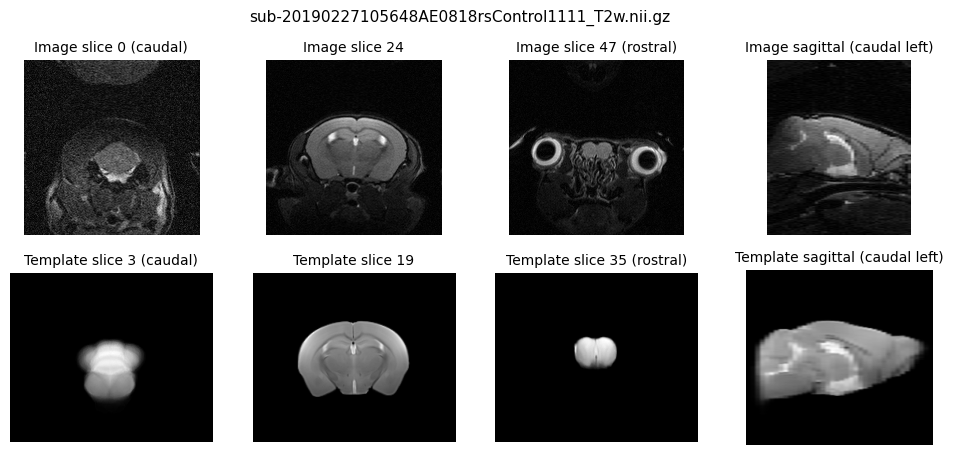

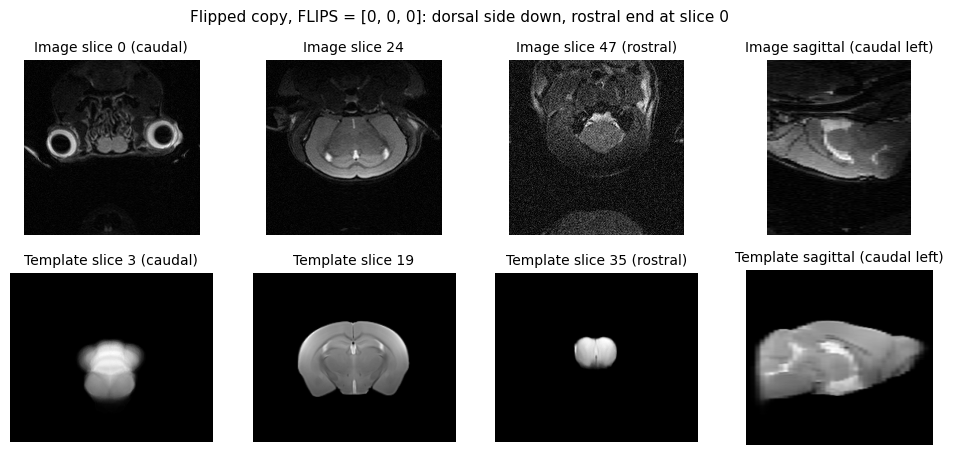

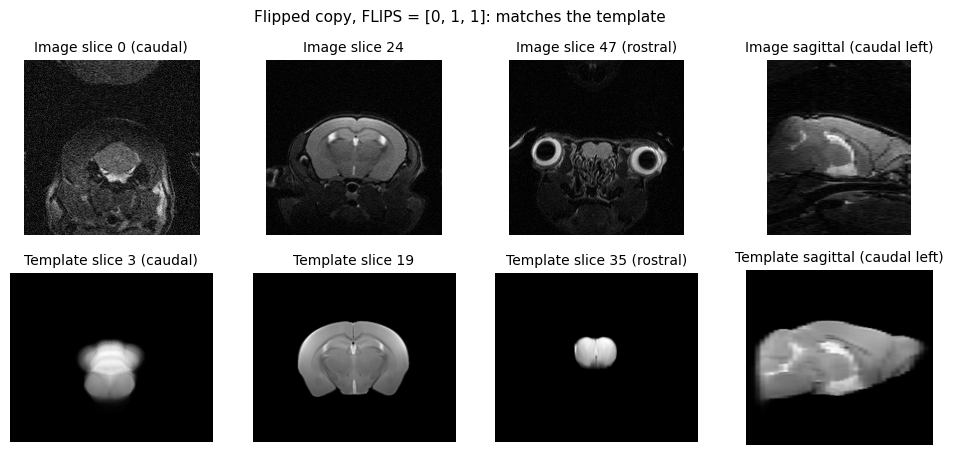

Fixed copy identical to the original image: True | inverse (masks) back on the copy's grid: True


In [5]:
PERM  = (0, 1, 2)  # Stored axis that becomes SAMson axis 0 (left-right), 1 (ventral -> dorsal) and 2 (caudal -> rostral)
FLIPS = [0, 0, 0]  # 1 = reverse that SAMson axis (e.g. [0, 1, 1] for an image stored upside down and rostral -> caudal)

# Re-run this cell until your image (top) looks like the template (bottom)
example = pjoin(subjects_path, example_file)
zooms = np.array(nib.load(example).header.get_zooms()[:3])
show_orientation(load_volume(example), zooms[list(PERM)], os.path.basename(example))

# Demonstration on a copy of the image stored upside down and rostral -> caudal: detected with [0, 0, 0], fixed with [0, 1, 1]
flipped = np.flip(load_volume_original(example), axis=(1, 2))
show_orientation(to_samson(flipped, PERM, [0, 0, 0]), zooms, "Flipped copy, FLIPS = [0, 0, 0]: dorsal side down, rostral end at slice 0")
show_orientation(to_samson(flipped, PERM, [0, 1, 1]), zooms, "Flipped copy, FLIPS = [0, 1, 1]: matches the template")
print("Fixed copy identical to the original image:", np.array_equal(to_samson(flipped, PERM, [0, 1, 1]), load_volume(example)),
      "| inverse (masks) back on the copy's grid:", np.array_equal(to_stored(to_samson(flipped, PERM, [0, 1, 1]), PERM, [0, 1, 1]), flipped))


## Full-Auto

List of files to segment:

sub-20190227105648AE0818rsControl1111_T2w.nii.gz
sub-20190227120644AE0818rsControl1211_T2w.nii.gz
sub-20190227125730AE0818rsControl1311_T2w.nii.gz
sub-20190228081325AE0818rsControl1411_T2w.nii.gz
sub-20190228093749AE0818rsControl2111_T2w.nii.gz
sub-20190228103014AE0818rsControl1511_T2w.nii.gz
sub-20190311083410AE0818rsControl1112_T2w.nii.gz
sub-20190311095840AE0818rsControl1212_T2w.nii.gz
sub-20190311105918AE0818rsControl1312_T2w.nii.gz
sub-20190311115813AE0818rsControl1412_T2w.nii.gz
sub-20190311125036AE0818rsControl1512_T2w.nii.gz
sub-20190311143920AE0818rsControl2112_T2w.nii.gz

-------------------------------------------------

Subject filename: sub-20190227105648AE0818rsControl1111_T2w.nii.gz

✅ Automatic generation of input boxes completed in 0.03 minutes
✅  [◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼] 100.0%  - extraction completed in 0.56 minutes


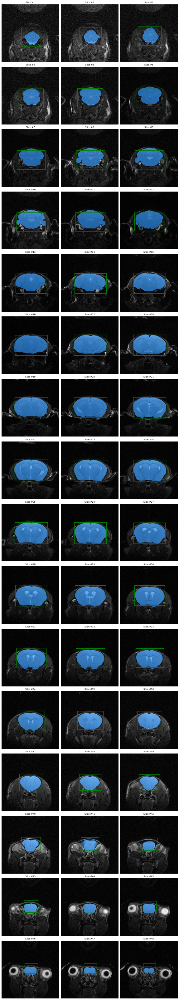

In [6]:
# Create a list of image files for segmentation
files = [file for file in sorted(os.listdir(subjects_path)) if is_subject(file)]
output_path = pjoin(output_path_b, "full_auto")
os.makedirs(output_path, exist_ok=True)
print("List of files to segment:\n", *files, sep="\n")

# Generate SAMson masks and visualize the corresponding predictions
candidates = {}
for file in [example_file]:  # Only the example subject
    print(f"\n{'-' * 49}\n\nSubject filename: {file}\n")
    candidates[file] = create_sam_candidates_list(file, reorient=False)

In [7]:
# Save the masks as NIfTI files in the designated output path (they are displayed above)
for file in [example_file]:  # Only the example subject
    create_sam_masks_nifti(file, candidates[file], show=False)
    print(f"Mask of {file} saved in {os.path.relpath(output_path)}")

Mask of sub-20190227105648AE0818rsControl1111_T2w.nii.gz saved in SAMson_outputs/full_auto


## Semi-Auto

List of files to segment:

sub-20190227105648AE0818rsControl1111_T2w.nii.gz
sub-20190227120644AE0818rsControl1211_T2w.nii.gz
sub-20190227125730AE0818rsControl1311_T2w.nii.gz
sub-20190228081325AE0818rsControl1411_T2w.nii.gz
sub-20190228093749AE0818rsControl2111_T2w.nii.gz
sub-20190228103014AE0818rsControl1511_T2w.nii.gz
sub-20190311083410AE0818rsControl1112_T2w.nii.gz
sub-20190311095840AE0818rsControl1212_T2w.nii.gz
sub-20190311105918AE0818rsControl1312_T2w.nii.gz
sub-20190311115813AE0818rsControl1412_T2w.nii.gz
sub-20190311125036AE0818rsControl1512_T2w.nii.gz
sub-20190311143920AE0818rsControl2112_T2w.nii.gz

-------------------------------------------------

Subject filename: sub-20190227105648AE0818rsControl1111_T2w.nii.gz

✅ Automatic generation of input boxes completed in 0.03 minutes
✅  [◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼] 100.0%  - extraction completed in 0.46 minutes





In [8]:
# Create a list of image files for segmentation
files = [file for file in sorted(os.listdir(subjects_path)) if is_subject(file)]
output_path = pjoin(output_path_b, "semi_auto")
os.makedirs(output_path, exist_ok=True)
print("List of files to segment:\n", *files, sep="\n")

# Generate SAMson masks and visualize the corresponding predictions
candidates = {}
for file in [example_file]:  # Only the example subject
    print(f"\n{'-' * 49}\n\nSubject filename: {file}\n")
    candidates[file] = create_sam_candidates_list(file, semi_auto=True, reorient=False)

In [9]:
# The following step requires a reference mask (see the Accuracy analysis section):
# best_mask_indexes = [find_best_mask_indexes(candidates[file]["metrics"]) for file in files]

# Otherwise, manually specify the optimal output indices for each slice as follows:
# best_mask_indexes = [[0,1,2,1,2,0,...],
#                             ...       ,
#                      [...............]]
best_mask_indexes = [[1] * 48]  # The example subject has 48 slices: second candidate on every slice

print(best_mask_indexes)

[[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]



-------------------------------------------------

Subject filename: sub-20190227105648AE0818rsControl1111_T2w.nii.gz



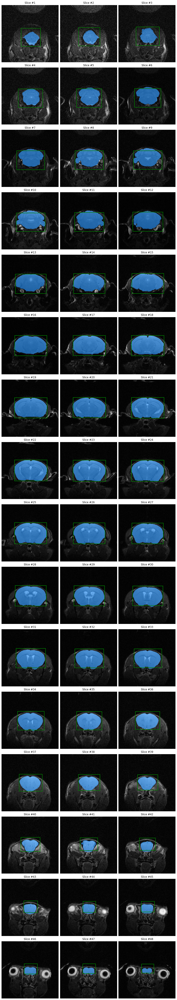

In [10]:
# Save the masks as NIfTI files in the designated output path
for file, best_mask_index in zip([example_file], best_mask_indexes):
    print(f"\n{'-' * 49}\n\nSubject filename: {file}\n")
    create_sam_masks_nifti(file, candidates[file], best_mask_index=best_mask_index)  # type: ignore

## Accuracy analysis

In this section, we demonstrate the segmentation of images with existing manual masks, utilizing the evaluation functions for analysis. All 12 scans of D3 are segmented; the outputs of the example subject (the scan with the median Full-Auto Jaccard index of D3) are shown. The per-subject means printed by these functions average every slice of the anteroposterior range, including slices without brain in the reference mask, where the Jaccard index is 0 (the first two slices of the example subject: 90.51% Full-Auto). The article and `SAMson_experiments.ipynb` evaluate only the slices with brain in the reference mask, which gives 94.44% for this scan, the median of D3.

In [11]:
subjects_path = pjoin(publication, "datasets/D3/anat")  # Folder with already extracted files to show evaluation
is_subject    = lambda file: file.startswith("sub-") and file.endswith("_T2w.nii.gz")
reference_path = lambda file: pjoin(publication, "datasets/D3/anat/manual_masks", file.replace(".nii.gz", "_mask.nii.gz"))  # Reference mask of each subject (adapt it)
# Remember to adjust the anteroposterior range for correct input prompt generation
initial_slice =  3
final_slice   = 35
from IPython.utils.capture import capture_output  # Hides the outputs of all subjects but the example subject

### Full-Auto

List of files to segment:

sub-20190227105648AE0818rsControl1111_T2w.nii.gz
sub-20190227120644AE0818rsControl1211_T2w.nii.gz
sub-20190227125730AE0818rsControl1311_T2w.nii.gz
sub-20190228081325AE0818rsControl1411_T2w.nii.gz
sub-20190228093749AE0818rsControl2111_T2w.nii.gz
sub-20190228103014AE0818rsControl1511_T2w.nii.gz
sub-20190311083410AE0818rsControl1112_T2w.nii.gz
sub-20190311095840AE0818rsControl1212_T2w.nii.gz
sub-20190311105918AE0818rsControl1312_T2w.nii.gz
sub-20190311115813AE0818rsControl1412_T2w.nii.gz
sub-20190311125036AE0818rsControl1512_T2w.nii.gz
sub-20190311143920AE0818rsControl2112_T2w.nii.gz

-------------------------------------------------

Subject filename: sub-20190227105648AE0818rsControl1111_T2w.nii.gz

✅ Automatic generation of input boxes completed in 0.03 minutes
✅  [◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼] 100.0%  - extraction completed in 0.44 minutes
slice      1    2        3        4        5        6        7        8        9        10       11       12       13       14  

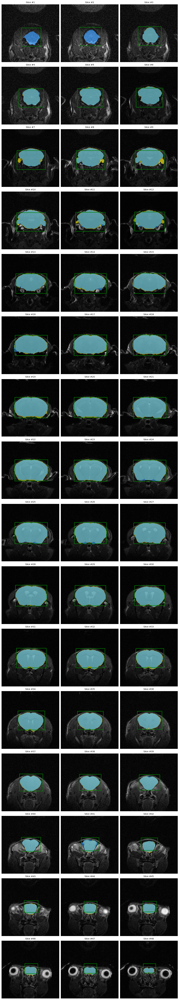

In [12]:
# Create a list of image files for segmentation
files = [file for file in sorted(os.listdir(subjects_path)) if is_subject(file)]
output_path = pjoin(output_path_b, "full_auto/D3")
os.makedirs(output_path, exist_ok=True)
print("List of files to segment:\n", *files, sep="\n")

# Generate SAMson masks and visualize the corresponding predictions
candidates = {}
for i, file in enumerate(files):  # All files
    with capture_output(stdout=file != example_file, display=file != example_file):  # Outputs of the example subject only
        print(f"\n{'-' * 49}\n\nSubject filename: {file}\n")
        candidates[file] = create_sam_candidates_list(file, reference_mask=True, reorient=False)

In [13]:
# Save the masks as NIfTI files in the designated output path (masks and metrics are displayed above)
results = {}
for file in files:  # All files
    results[file] = create_sam_masks_nifti(file, candidates[file], show=False)
print(f"Masks of {len(results)} subjects saved in {os.path.relpath(output_path)}")

print("\nALL SUBJECTS PERFORMANCE METRICS (mean values per subject):")
print(pd.DataFrame({file: subject_means(metrics) for file, metrics in results.items()}).T.to_string())

Masks of 12 subjects saved in SAMson_outputs/full_auto/D3

ALL SUBJECTS PERFORMANCE METRICS (mean values per subject):
                                                  accuracy  jaccard    dice
sub-20190227105648AE0818rsControl1111_T2w.nii.gz     90.45   0.9051  0.9308
sub-20190227120644AE0818rsControl1211_T2w.nii.gz     82.34   0.8998  0.9227
sub-20190227125730AE0818rsControl1311_T2w.nii.gz     88.89   0.8900  0.9129
sub-20190228081325AE0818rsControl1411_T2w.nii.gz   -273.51   0.9021  0.9256
sub-20190228093749AE0818rsControl2111_T2w.nii.gz     86.31   0.8703  0.8918
sub-20190228103014AE0818rsControl1511_T2w.nii.gz     85.36   0.8639  0.8880
sub-20190311083410AE0818rsControl1112_T2w.nii.gz     65.75   0.8684  0.8924
sub-20190311095840AE0818rsControl1212_T2w.nii.gz     88.91   0.8930  0.9141
sub-20190311105918AE0818rsControl1312_T2w.nii.gz     17.58   0.8735  0.8940
sub-20190311115813AE0818rsControl1412_T2w.nii.gz     28.66   0.8619  0.8932
sub-20190311125036AE0818rsControl1512_T2w.nii

### Semi-Auto

List of files to segment:

sub-20190227105648AE0818rsControl1111_T2w.nii.gz
sub-20190227120644AE0818rsControl1211_T2w.nii.gz
sub-20190227125730AE0818rsControl1311_T2w.nii.gz
sub-20190228081325AE0818rsControl1411_T2w.nii.gz
sub-20190228093749AE0818rsControl2111_T2w.nii.gz
sub-20190228103014AE0818rsControl1511_T2w.nii.gz
sub-20190311083410AE0818rsControl1112_T2w.nii.gz
sub-20190311095840AE0818rsControl1212_T2w.nii.gz
sub-20190311105918AE0818rsControl1312_T2w.nii.gz
sub-20190311115813AE0818rsControl1412_T2w.nii.gz
sub-20190311125036AE0818rsControl1512_T2w.nii.gz
sub-20190311143920AE0818rsControl2112_T2w.nii.gz

-------------------------------------------------

Subject filename: sub-20190227105648AE0818rsControl1111_T2w.nii.gz

✅ Automatic generation of input boxes completed in 0.02 minutes
✅  [◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼◼] 100.0%  - extraction completed in 0.48 minutes
Jaccard index of each candidate:
candidate       0       1       2
slice                            
1          0.0000  0.0000  




In [14]:
# Create a list of image files for segmentation
files = [file for file in sorted(os.listdir(subjects_path)) if is_subject(file)]
output_path = pjoin(output_path_b, "semi_auto/D3")
os.makedirs(output_path, exist_ok=True)
print("List of files to segment:\n", *files, sep="\n")

# Generate SAMson masks and visualize the corresponding predictions
candidates = {}
for i, file in enumerate(files):  # All files
    with capture_output(stdout=file != example_file, display=file != example_file):  # Outputs of the example subject only
        print(f"\n{'-' * 49}\n\nSubject filename: {file}\n")
        candidates[file] = create_sam_candidates_list(file, semi_auto=True, reference_mask=True, reorient=False)

In [15]:
# The following step requires a reference mask
best_mask_indexes = [find_best_mask_indexes(candidates[file]["metrics"]) for file in files]

# Otherwise, manually specify the optimal output indices for each slice as follows:
# best_mask_indexes = [[0,1,2,1,2,0,...],
#                             ...       ,
#                      [...............]]

for file, indexes in zip(files, best_mask_indexes):  # Selected candidate of each slice, one subject per line
    print(f"{file.split('.')[0]}: {[int(index) for index in indexes]}")

sub-20190227105648AE0818rsControl1111_T2w: [0, 0, 0, 0, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2]
sub-20190227120644AE0818rsControl1211_T2w: [0, 0, 0, 2, 1, 2, 1, 2, 1, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 0, 1, 2, 2, 2, 2, 2, 2, 1]
sub-20190227125730AE0818rsControl1311_T2w: [0, 0, 0, 2, 1, 2, 0, 2, 1, 1, 0, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 2, 2, 2, 2, 1, 1, 0]
sub-20190228081325AE0818rsControl1411_T2w: [0, 0, 0, 0, 0, 1, 0, 2, 1, 1, 1, 0, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 1, 0, 1, 2, 2, 2, 1, 2, 2, 1]
sub-20190228093749AE0818rsControl2111_T2w: [0, 0, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 2, 2, 2, 2, 2, 2, 1, 2, 2, 1, 2, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 0, 0, 1, 1, 2, 2, 2, 2, 0, 0]
sub-20190228103014AE0818rsControl1511_T2w: [0, 0, 0, 0, 2, 2


-------------------------------------------------

Subject filename: sub-20190227105648AE0818rsControl1111_T2w.nii.gz

slice      1    2        3        4        5        6        7        8        9        10       11       12      13       14       15       16       17       18       19       20       21       22       23       24       25       26       27       28       29       30       31       32       33       34       35       36       37       38       39       40       41       42       43       44       45       46       47       48
accuracy  0.0  0.0  96.1200  95.8400  96.7300  96.9000  92.2000  93.0500  95.7400  94.9900  92.3600  90.3000  95.480  92.9800  94.9600  95.1300  96.3000  95.9400  94.6400  95.4500  96.0900  94.6300  96.7600  95.9600  96.3800  94.6600  95.5500  95.8500  96.1800  96.6700  96.0000  95.2300  94.7200  96.3700  95.7400  96.0800  97.6900  96.2700  96.7200  95.7500  93.0500  92.0100  93.4800  93.6600  94.2600  92.3500  92.2800  92.3200
jaccard   0.0  0

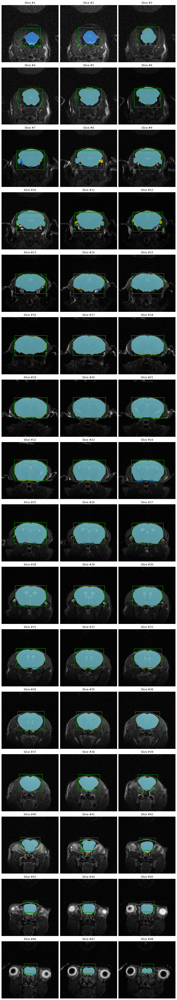


ALL SUBJECTS PERFORMANCE METRICS (mean values per subject):
                                                  accuracy  jaccard    dice
sub-20190227105648AE0818rsControl1111_T2w.nii.gz     91.00   0.9103  0.9336
sub-20190227120644AE0818rsControl1211_T2w.nii.gz     82.91   0.9037  0.9248
sub-20190227125730AE0818rsControl1311_T2w.nii.gz     89.71   0.8976  0.9170
sub-20190228081325AE0818rsControl1411_T2w.nii.gz   -248.77   0.9074  0.9286
sub-20190228093749AE0818rsControl2111_T2w.nii.gz     88.52   0.8855  0.9008
sub-20190228103014AE0818rsControl1511_T2w.nii.gz     87.90   0.8796  0.8977
sub-20190311083410AE0818rsControl1112_T2w.nii.gz     67.24   0.8741  0.8960
sub-20190311095840AE0818rsControl1212_T2w.nii.gz     90.37   0.9041  0.9204
sub-20190311105918AE0818rsControl1312_T2w.nii.gz     22.31   0.8849  0.9012
sub-20190311115813AE0818rsControl1412_T2w.nii.gz     36.34   0.8814  0.9064
sub-20190311125036AE0818rsControl1512_T2w.nii.gz     87.65   0.8773  0.8965
sub-20190311143920AE0818rsC

In [16]:
# Save the masks as NIfTI files in the designated output path
results = {}
for i, (file, best_mask_index) in enumerate(zip(files, best_mask_indexes)):  # All files
    with capture_output(stdout=file != example_file, display=file != example_file):  # Outputs of the example subject only
        print(f"\n{'-' * 49}\n\nSubject filename: {file}\n")
        results[file] = create_sam_masks_nifti(file, candidates[file], best_mask_index=best_mask_index)

print("\nALL SUBJECTS PERFORMANCE METRICS (mean values per subject):")
print(pd.DataFrame({file: subject_means(metrics) for file, metrics in results.items()}).T.to_string())

In [17]:
# Check: the masks are voxel-identical to those of the full run (outputs/masks/samson_full_auto|samson_semi_auto/D3/anat)
for mode in ("full_auto", "semi_auto"):
    run = pjoin(publication, "outputs/masks", f"samson_{mode}", "D3/anat")
    same = [np.array_equal(nib.load(pjoin(output_path_b, mode, "D3", mask)).get_fdata(), nib.load(pjoin(run, mask)).get_fdata()) for mask in sorted(os.listdir(run))]
    print(f"{mode}: {sum(same)}/{len(same)} masks voxel-identical to the full run")

full_auto: 12/12 masks voxel-identical to the full run
semi_auto: 12/12 masks voxel-identical to the full run
